---
title: "The multivariate normal distribution"
description: "Densities in several dimensions, and the multivariate normal derived from symmetry requirements, with the covariance matrix and the density's contour lines."
---

## Densities of multivariate distributions

Recall: if $f \colon \mathbb{R} \to [0,\infty)$ is a density function belonging to the distribution $P$ of a real random variable $X$, then $P(X < c) = \int_{-\infty}^c f(x)dx$.

Generalising this to two dimensions, that is, to a random variable $(X,Y)$ with values in $\mathbb{R}^2$, gives $P(X < c, Y < d) = \int_{-\infty}^c \int_{-\infty}^d f(x,y)\,dy\,dx$.

So the density function must have the signature $f \colon \mathbb{R}^2 \to [0,\infty)$: it encodes a probability density for every possible value of $(X,Y)$.

More generally, a function $f \colon \mathbb{R}^n \to [0,\infty)$ with $\int_{\mathbb{R}^n} f(x)dx = 1$ defines a probability measure $P$ by $P(A) = \int_A f(x)dx$, and $f$ is called a density for the distribution $P$.

## Derivation: from the symmetry to the formula

Before we define the multidimensional normal distribution, we want to find it. The question is: which distribution on the plane $\mathbb{R}^2$ plays the role that $\mathcal{N}(0,1)$ plays on the line? The one-dimensional normal distribution has two properties that single it out: it is symmetric about its expected value, and among all distributions with a given variance it is the one with the greatest entropy, that is, the one that assumes nothing beyond its expected value and variance (see [The normal distribution](normal-distribution.ipynb); exactly what entropy means for continuous distributions is settled in the chapter [Relative entropy](relative-entropy.md)).

We already know one way of building a two-dimensional distribution out of two one-dimensional ones: the **product distribution** of two independent random variables, whose density is the product of the two densities. Let us try out a few candidates and look down on the density from above:


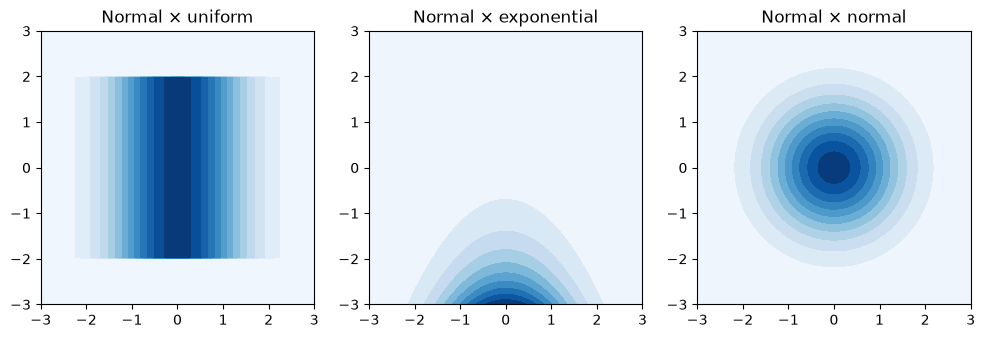

In [1]:
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt

xs = np.linspace(-3, 3, 200)
X, Y = np.meshgrid(xs, xs)
candidates = {
    "Normal × uniform":     st.norm.pdf(X) * st.uniform.pdf(Y, loc=-2, scale=4),
    "Normal × exponential": st.norm.pdf(X) * st.expon.pdf(Y + 3),
    "Normal × normal":      st.norm.pdf(X) * st.norm.pdf(Y),
}
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
for ax, (name, density) in zip(axs, candidates.items()):
    ax.contourf(X, Y, density, levels=12, cmap="Blues")
    ax.set_title(name)
    ax.set_aspect("equal")
plt.show()


Only the third picture is **rotationally symmetric**: you can turn it about the origin without anything changing. That is no accident; it is a calculation:

$$
\phi(x)\,\phi(y) = \frac{1}{2\pi}\, e^{-x^2/2}\, e^{-y^2/2} = \frac{1}{2\pi}\, e^{-(x^2+y^2)/2} = \frac{1}{2\pi}\, e^{-r^2/2},
$$

the density depends only on the distance $r$ from the origin. The product of two standard normal distributions is therefore the "most symmetric" distribution on the plane, and it inherits the maximum entropy property. This is our **standard normal distribution in two dimensions**, and in $n$ dimensions it works the same way: $\phi(z) = (2\pi)^{-n/2} e^{-\lVert z \rVert^2/2}$ for $z \in \mathbb{R}^n$.

Every other normal distribution arises from it by three operations, which we add one at a time. Let $Z$ be standard normally distributed in $\mathbb{R}^n$.

1. **Shifting:** $X = Z + \mu$ has expected value $\mu$. The density is then evaluated at $z = x - \mu$.
2. **Scaling:** $X = DZ$ with a diagonal matrix $D = \operatorname{diag}(d_1,\dots,d_n)$ stretches the $i$-th axis by $d_i$. The variance in that direction becomes $d_i^2$, since $\mathbb{V}(d_i Z_i) = d_i^2 \mathbb{V}(Z_i)$: double the data and you quadruple the variance.
3. **Rotating:** $X = RZ$ with an orthogonal matrix $R$ (that is, $R^T R = I$) turns the cloud of points without changing any distances.

Put together: $X = A Z + \mu$ with $A = R D$. What density does $X$ have? We undo the transformation, $Z = A^{-1}(X - \mu)$, and substitute into $e^{-\lVert z \rVert^2/2}$. For the squared length, every matrix $M$ satisfies

$$
\lVert M z \rVert^2 = (Mz)^T (Mz) = z^T M^T M z,
$$

because transposing a product reverses the order of the factors. With $M = A^{-1}$ and $z = x - \mu$ the exponent therefore reads $(x-\mu)^T (A^{-1})^T A^{-1} (x - \mu) = (x-\mu)^T (A A^T)^{-1} (x-\mu)$. The matrix

$$
\Sigma := A A^T = R D^2 R^T
$$

is exactly the covariance matrix of $X$ (check this with the rules of calculation from the chapter [Covariance](covariance.md)), and $\Sigma^{-1}$ in the exponent **undoes the rotation and the stretching**: it measures the distance from $x$ to $\mu$ not with an ordinary ruler but in units of the spread in each direction. The normalising factor also picks up $\det(\Sigma)^{-1/2} = \lvert\det A\rvert^{-1}$, because the rotation and the stretching enlarge areas (volumes, in general) by $\lvert \det A \rvert$ and thin the density out accordingly.

We can follow this through on the computer: draw a standard normal sample, apply $A$ to it, and read $\Sigma$ and the stretch factors back off the sample:


Sigma = A A^T =
 [[3.063 1.624]
 [1.624 1.187]]
empirical covariance matrix of the sample:
 [[3.094 1.61 ]
 [1.61  1.164]]
square roots of the eigenvalues: [0.5 2. ] -- these are the stretch factors 1/2 and 2


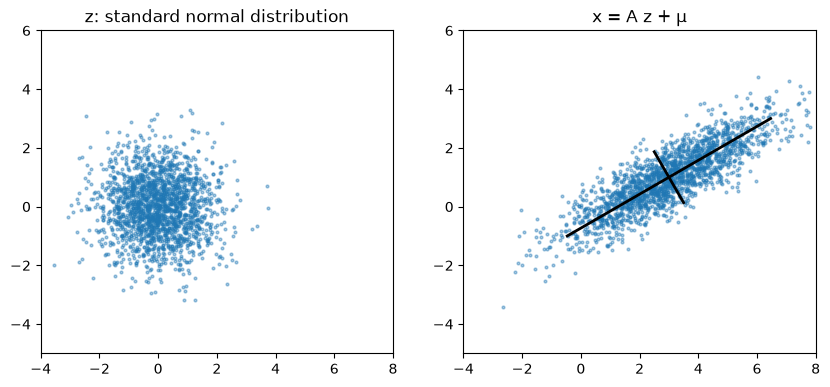

In [2]:
rng = np.random.default_rng(1)
z = rng.standard_normal((2000, 2))          # standard normal in the plane, one row per point
D = np.diag([2.0, 0.5])                     # scaling: axis 1 by 2, axis 2 by 1/2
phi = np.pi / 6                             # rotating by 30 degrees
R = np.array([[np.cos(phi), -np.sin(phi)],
              [np.sin(phi),  np.cos(phi)]])
mu = np.array([3.0, 1.0])                   # shifting
A = R @ D
x = z @ A.T + mu                            # x = A z + mu, row by row for all points

Sigma = A @ A.T
print("Sigma = A A^T =\n", Sigma.round(3))
print("empirical covariance matrix of the sample:\n", np.cov(x.T).round(3))
values, vectors = np.linalg.eigh(Sigma)     # Sigma is symmetric, hence eigh
print("square roots of the eigenvalues:", np.sqrt(values).round(3), "-- these are the stretch factors 1/2 and 2")

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs[0].scatter(z[:, 0], z[:, 1], s=4, alpha=0.4)
axs[0].set_title("z: standard normal distribution")
axs[1].scatter(x[:, 0], x[:, 1], s=4, alpha=0.4)
axs[1].set_title("x = A z + µ")
for i in range(2):                          # eigenvectors as the axes of the ellipse, length 2 standard deviations
    v = vectors[:, i] * np.sqrt(values[i]) * 2
    axs[1].plot([mu[0] - v[0], mu[0] + v[0]], [mu[1] - v[1], mu[1] + v[1]], color="black", lw=2)
for ax in axs:
    ax.set_aspect("equal"); ax.set_xlim(-4, 8); ax.set_ylim(-5, 6)
plt.show()


The black axes are the eigenvectors of $\Sigma$, scaled by the square roots of the eigenvalues: the rotation $R$ sits in the eigenvectors, the stretching $D$ in the eigenvalues. In practice this works the other way round: if your data have correlated features, you do not first have to "rotate them straight" before modelling them with a normal distribution. You substitute the empirical mean and the empirical covariance matrix directly into the formula, which we now record as a definition.


## The multivariate normal distribution

:::{admonition} Definition
Let $n \in \mathbb{N}$, let $\mu \in \mathbb{R}^n$ and let $\Sigma \in Mat(n \times n; \mathbb{R})$ be a positive definite symmetric matrix.

Then the distribution belonging to the density function


$$
\phi(x) = \dfrac{1}{\sqrt{(2\pi)^{n}\det(\Sigma)}} \exp\left( -\dfrac{ (x-\mu)^T \Sigma^{-1}(x-\mu) }{ 2 } \right)
$$

is called the *n-dimensional (multivariate) normal distribution with expected value $\mu$ and covariance matrix $\Sigma$*.
:::

This distribution really does have the expected value and the covariance matrix its name promises; it is also written $\mathcal{N}(\mu,\Sigma)$.

In deep learning, a *variational autoencoder* models every data point as a normal distribution $\mathcal{N}(\mu, \operatorname{diag}(\sigma^2))$ in a latent space, where $\mu$ and $\sigma$ are produced by the encoder network (the course *Introduction to Deep Learning*).

In [3]:
import numpy as np
import scipy.stats as st
import matplotlib.pyplot as plt

In [4]:
# instantiate a bivariate normal distribution:
def getmvn_by_rho(rho=0.7):
    origin = [0, 0]
    Sigma = np.array([[1,   rho],
                      [rho,   1]])
    Z = st.multivariate_normal(mean=origin, cov=Sigma)
    return Sigma, Z

In [5]:
# draw a sample:
def samplexy(Sigma, Z, size=1000000):
    sample = Z.rvs(size=size)
    x, y = sample[:,0], sample[:,1]
    # sample covariance == Sigma
    assert np.all(np.isclose(Sigma,
                             np.round(np.cov(x,y),
                                      decimals=2)))
    return x, y

Tip: read up on how *meshgrids* work in Numpy (and, with them, the function mgrid). A hint: a meshgrid is a kind of explicit broadcasting done in advance, so that the arithmetic afterwards runs vectorised and faster. Try it out yourself on small meshgrids by evaluating a function of two variables, $x^2+y^2$ say, on a meshgrid in vectorised form.

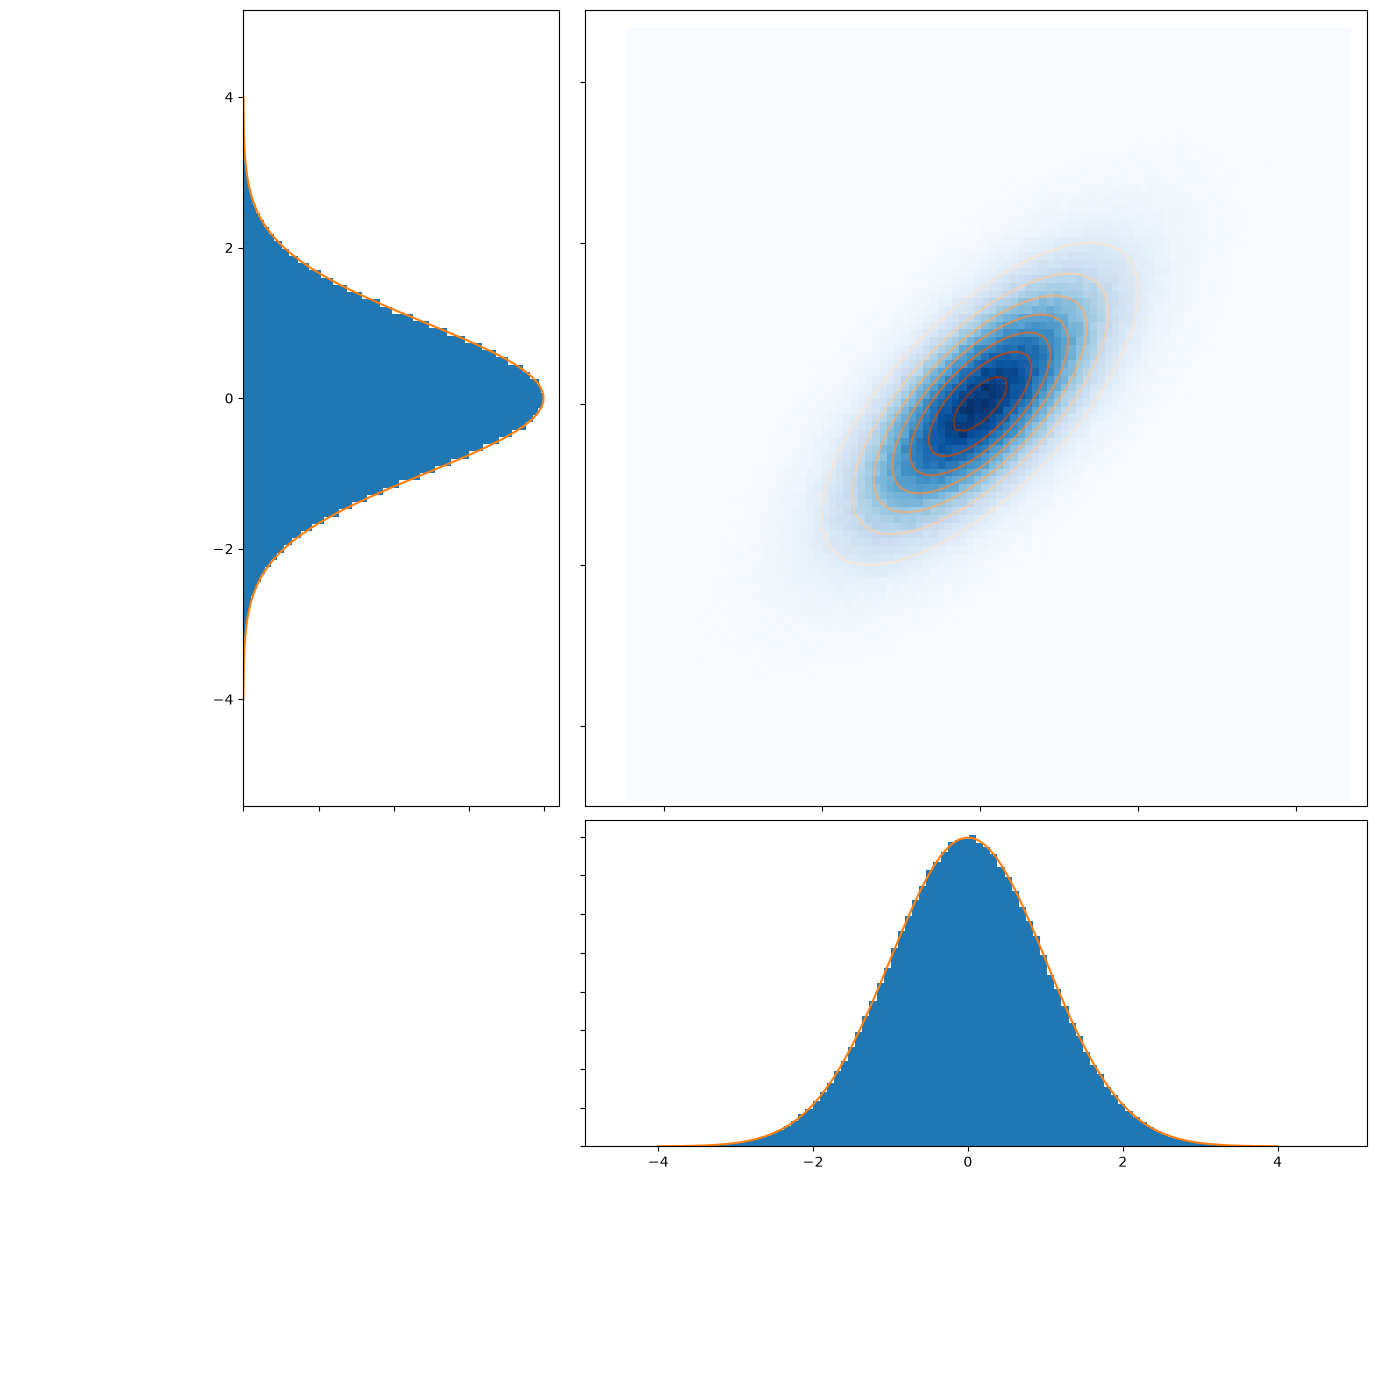

In [6]:
# 2D plotting:
def plotalot(x, y, Z):
    fig, axs = plt.subplots(2,2, figsize=(9,9))
    fig.tight_layout(pad=-18)   # negative padding: the marginal histograms should sit right up against the main plot
    axs[0,1].hist2d(x, y, bins=100, cmap=plt.cm.Blues)
    xs, ys = np.mgrid[-5:5:.1, -5:5:.1] # meshgrid
    axs[0,1].contour(xs, ys,
                     Z.pdf(np.dstack((xs, ys))),
                     cmap=plt.cm.Oranges, alpha=.7)
    axs[0,1].set_xticklabels([])
    axs[0,1].set_yticklabels([])
    axs[1,1].hist(x, bins=100, density=True)
    axs[1,1].plot(xl := np.linspace(-4,4,100),
                  st.norm.pdf(xl, loc=0, scale=1))
    axs[1,1].set_yticklabels([])
    axs[1,1].set_aspect(10)
    axs[0,0].hist(y, bins=100, density=True,
                  orientation="horizontal")
    axs[0,0].plot(st.norm.pdf(yl := np.linspace(-4,4,100), loc=0, scale=1),
                  yl)
    axs[0,0].set_xticklabels([])
    axs[0,0].set_aspect(0.1)
    axs[1,0].set_axis_off()
    plt.show()

def plot_by_rho(rho=0.7):
    Sigma, Z = getmvn_by_rho(rho)
    x, y = samplexy(Sigma, Z)
    plotalot(x, y, Z)
    
plot_by_rho()

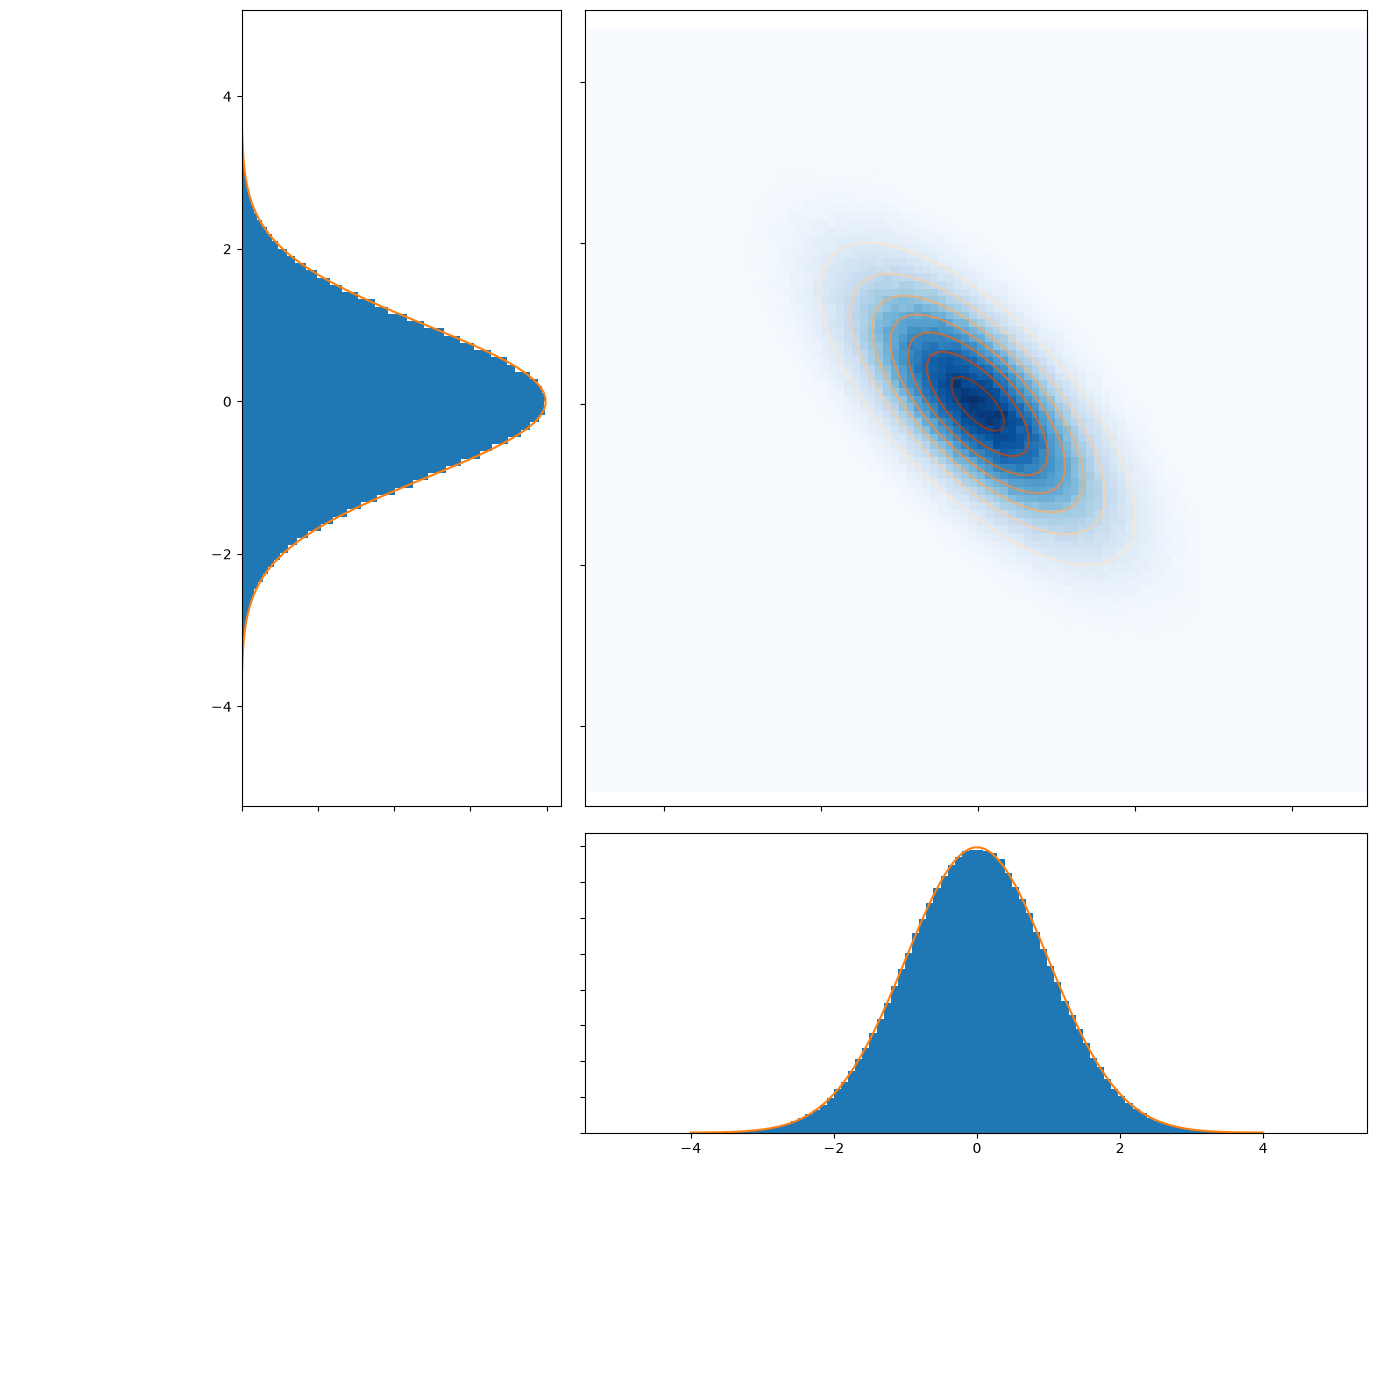

In [7]:
# negatively correlated looks like this:
plot_by_rho(-0.7)

So the marginal distributions look exactly the same – the correlation shows only in the joint distribution, where it is plain enough to see: in the two-dimensional histogram (also called a heatmap) and in the contour plot (the ellipses).

The covariance matrix has a direct geometric interpretation: every positive definite symmetric matrix $A$ defines an inner product $\langle v, w \rangle_A := \langle Av, w\rangle = (Av)^Tw = v^TA^Tw = v^TAw = \langle v, Aw\rangle$ and with it a so-called quadratic form $v \mapsto \langle v, v \rangle_A$. The contour lines (level sets) of the quadratic form are ellipses, with the same axes as the contour lines of the corresponding normal distribution.

The formula defining the density of the multivariate normal distribution contains the expression $v^T \Sigma^{-1} v$ for the vector $v = x - \mu$, and that is exactly the inner product defined by the matrix $\Sigma^{-1}$. The density is therefore $c \cdot e^{-Q(v)/2}$ with $Q(v) := v^T \Sigma^{-1} v$ and a constant $c$, and the level sets of the density are precisely the level sets of $Q$. For $\Sigma = \begin{pmatrix} 1 & \rho \\ \rho & 1 \end{pmatrix}$ we have $\Sigma^{-1} = \frac{1}{1-\rho^2}\begin{pmatrix} 1 & -\rho \\ -\rho & 1 \end{pmatrix}$.

:::{admonition} Remark
**The multivariate normal distribution is always unimodal.** Because $\Sigma^{-1}$ is positive definite, $Q(v) \geq 0$ with equality only for $v = 0$, and along every ray leading away from $\mu$ the form $Q$ is strictly increasing. The density $c \cdot e^{-Q(v)/2}$ therefore has exactly one maximum, at $x = \mu$, and falls off from it in every direction – whatever $\Sigma$ looks like, including a negative covariance or very different variances. The covariance matrix deforms the peak into an ellipse; it cannot create a second one. So if a two-dimensional histogram shows two peaks, that is a sure sign that the data do *not* come from a single normal distribution – but rather, say, from a mixture of several, as in the chapter [Expectation Maximization](expectation-maximization.ipynb).
:::

The covariance matrix encodes exactly how the ellipse arises from a perfect circle. The circle corresponds to the identity matrix as covariance matrix, and $\Sigma = R D^2 R^\top$ from the derivation above says in which directions (the columns of $R$) and how strongly (the squares of the entries of $D$) the stretching happens. $\Sigma$ itself, being symmetric, rotates nothing; $\Sigma^{-1}$ has the same eigenvectors and compresses where $\Sigma$ stretches. That is precisely why $\Sigma^{-1}$ in the density undoes the stretching and measures the distance to $\mu$ in units of the spread.

To get a better grip on the geometry, start with bivariate normal distributions and make the matrix $\Sigma$ more complicated step by step (multiples of the identity matrix, diagonal matrices with different entries on the diagonal, arbitrary matrices). Any covariance matrix $\Sigma$ whatsoever can be brought into diagonal form by an orthogonal change of basis, which is to say that rotating the space makes the ellipse (the contour line of the normal distribution) parallel to the axes. Scaling the axes then turns the ellipse into a circle. Seen that way, every normal distribution is a standard normal distribution, just in different coordinates.


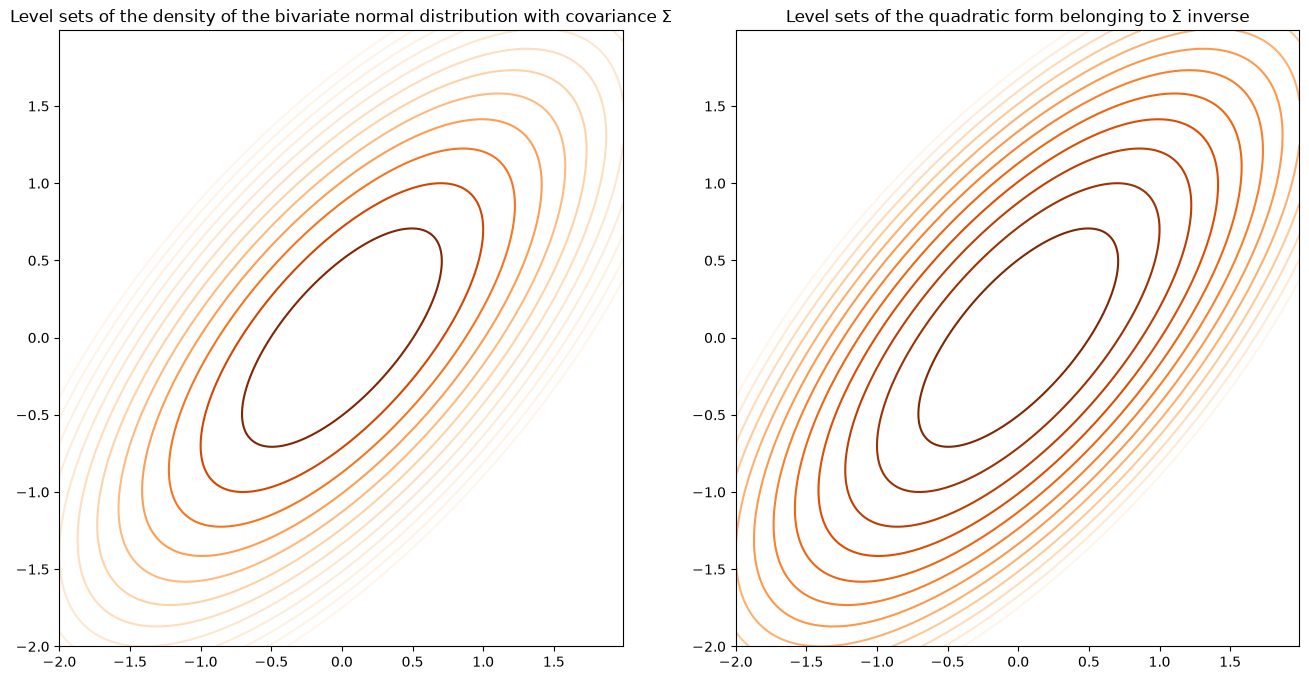

In [8]:
rho = 0.7
Sigma, Z = getmvn_by_rho(rho)
Sigma_inv = np.linalg.inv(Sigma)   # = 1/(1-rho^2) * [[1, -rho], [-rho, 1]]

def Q(x, y):
    """Quadratic form v^T Σ^{-1} v for v = (x, y)"""
    return Sigma_inv[0,0]*x**2 + 2*Sigma_inv[0,1]*x*y + Sigma_inv[1,1]*y**2

xs, ys = np.mgrid[-2:2:.01, -2:2:.01]

# The density is c * exp(-Q/2) with c = 1/(2 pi sqrt(det Σ)). On the left and on the right
# we draw the same levels, so that you can see they are the same ellipses:
levels_Q = np.arange(0.5, 6.5, 0.5)
c = 1 / (2 * np.pi * np.sqrt(np.linalg.det(Sigma)))
levels_pdf = np.sort(c * np.exp(-levels_Q / 2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8))
ax1.contour(xs, ys,
            Z.pdf(np.dstack((xs, ys))),
            levels=levels_pdf,
            cmap=plt.cm.Oranges)
ax1.set_title("Level sets of the density of the bivariate normal distribution with covariance Σ")
ax2.contour(xs, ys, Q(xs, ys),
            levels=levels_Q,
            cmap=plt.cm.Oranges_r)
ax2.set_title("Level sets of the quadratic form belonging to Σ inverse")

plt.show()

The axes of the ellipses can also be computed: they are the eigenvectors of $\Sigma$, and the square roots of the eigenvalues give (up to a common factor) the lengths of the semi-axes. For $\Sigma = \begin{pmatrix} 1 & \rho \\ \rho & 1 \end{pmatrix}$ these are the two diagonals, with eigenvalues $1+\rho$ and $1-\rho$. The chapter on [Dimensionality reduction](dimensionality-reduction.ipynb) builds precisely on this eigendecomposition:

In [9]:
values, vectors = np.linalg.eigh(Sigma)   # Sigma is symmetric, hence eigh (eigenvalues in ascending order)
print("Eigenvalues:", values)             # 1 - rho and 1 + rho
print("Eigenvectors (columns):")
print(vectors)                            # (1,-1)/√2 and (1,1)/√2: the axes of the ellipses

Eigenvalues: [0.3 1.7]
Eigenvectors (columns):
[[-0.70710678  0.70710678]
 [ 0.70710678  0.70710678]]


To get to know three-dimensional plotting with matplotlib as well, let us take another look at the density function of the normal distribution:

In [10]:
# 3D plotting:
from mpl_toolkits.mplot3d import axes3d

rho = 0.5
Sigma, Z = getmvn_by_rho(rho)

def plot3dangles(a, b, fig, where):
    ax = fig.add_subplot(where, projection='3d')
    ax.view_init(a, b)
    ax.set_zticklabels([])
    ax.plot_surface(xs, ys, Z.pdf(np.dstack((xs, ys))),
                    rstride=5, cstride=5,
                    cmap='viridis_r', edgecolor='none')

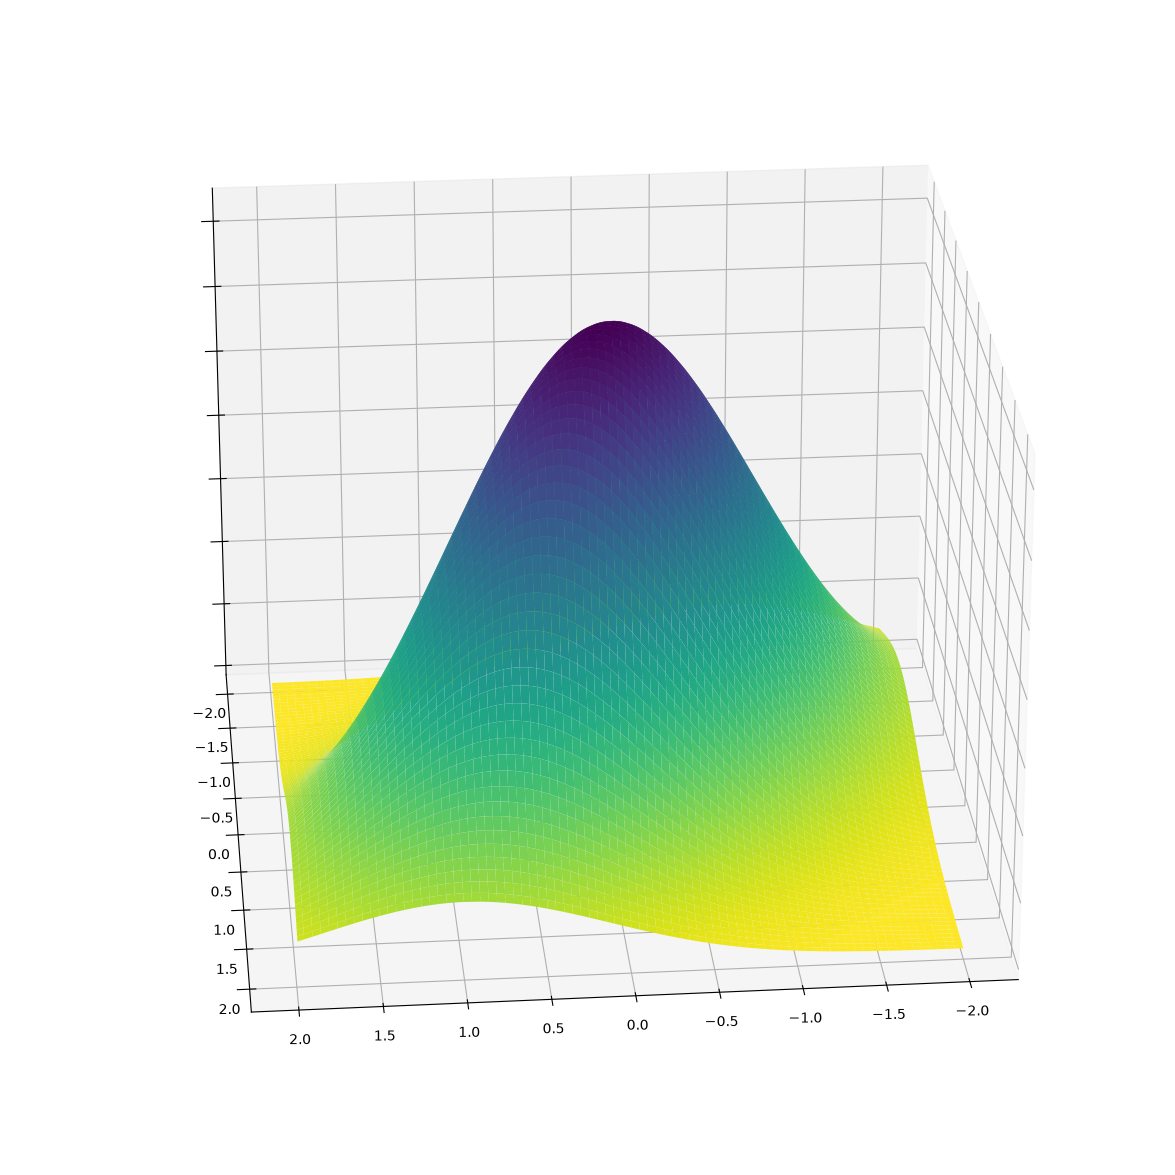

In [11]:
fig=plt.figure(figsize=(15,15))
plot3dangles(25, 85, fig, 111)
plt.show()

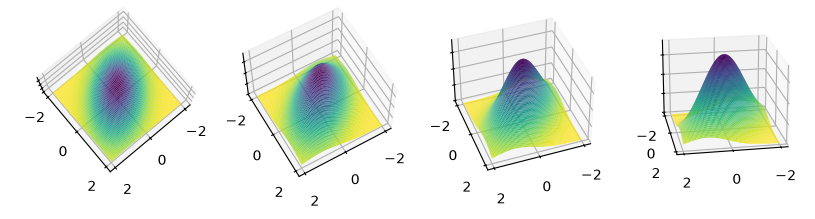

In [12]:
fig=plt.figure(figsize=(10,10))
plot3dangles(80, 50, fig, 141)
plot3dangles(60, 60, fig, 142)
plot3dangles(40, 70, fig, 143)
plot3dangles(20, 80, fig, 144)
plt.show()

:::{admonition} Lemma
The multivariate normal distribution with expected value $\mu$ and covariance $\Sigma$ is the distribution of maximal entropy among all distributions with this expected value and this covariance matrix whose support is all of $\mathbb{R}^n$.
:::

:::{admonition} Lemma
A random vector $X = (X_1,\dots,X_n)$ (that is, a multivariate distribution) is multivariate normally distributed if and only if every linear combination $\sum_{i=1}^n \lambda_i X_i$ is univariate normally distributed.
:::

**Careful**

This does not mean that every linear combination of normally distributed random variables is again normally distributed! Here is an example that could almost be from the Datasaurus: $X$ and $Y$ are each normally distributed on their own but dependent on one another – and bang, $X+Y$ is not normally distributed (because X+Y=0 has probability 50%):

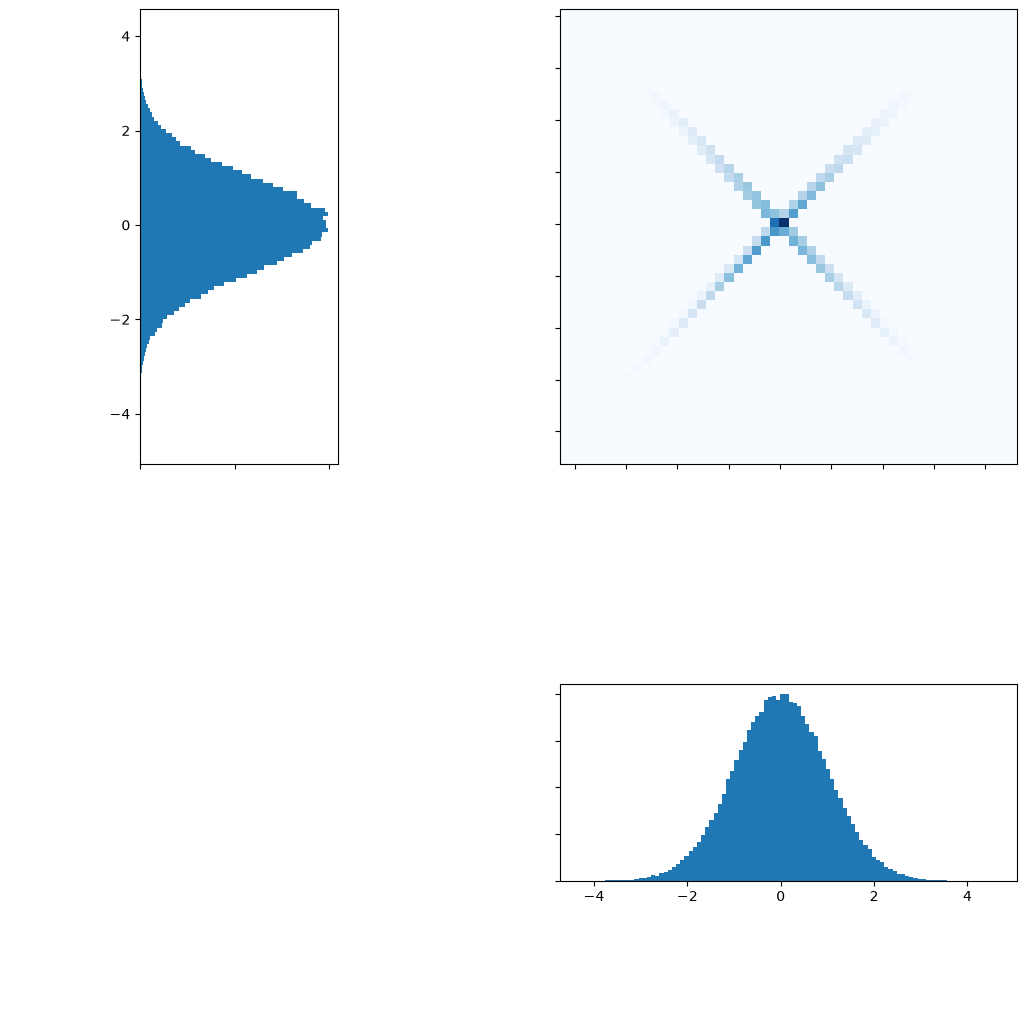

In [13]:
# plot the weirdo sample:
def plotalot2(x, y):
    fig, axs = plt.subplots(2,2, figsize=(13,13))
    axs[0,1].hist2d(x, y, bins=50, cmap=plt.cm.Blues)
    axs[0,1].set_xticklabels([])
    axs[0,1].set_yticklabels([])
    axs[1,1].hist(x, bins=100, density=True)
    axs[1,1].set_yticklabels([])
    axs[1,1].set_aspect(10)
    axs[0,0].hist(y, bins=100, density=True,
                  orientation="horizontal")
    axs[0,0].set_xticklabels([])
    axs[0,0].set_aspect(0.1)
    axs[1,0].set_axis_off()
    plt.show()

samplesize = 100000
x = st.norm.rvs(0, 1, size=samplesize)
t = 2*st.bernoulli.rvs(0.5, size=samplesize) - 1
y = t*x
plotalot2(x, y)

[Wikipedia has a nice article on the fact that normally distributed uncorrelated random variables can perfectly well be dependent on one another.](https://en.wikipedia.org/wiki/Normally_distributed_and_uncorrelated_does_not_imply_independent)

The random variables X, Y from the previous plot are exactly such an example: their correlation coefficient is $0$.

In the other direction there is a statement with strong hypotheses:

:::{admonition} Lemma
If $X$ and $Y$ are two real random variables that are jointly bivariate normally distributed, that is $(X,Y) \sim \mathcal{N}(\mu,\Sigma)$, then $X$ and $Y$ are independent as soon as they are uncorrelated.

The converse holds as well: if $X$ and $Y$ are each univariate normally distributed *and* independent, then $(X,Y)$ is bivariate normally distributed.
:::

**Exercise**:

Convince yourself that you know what the covariance matrix looks like in the case of independence.